# 기초데이터과학 (01분반)

## Lab 10. 데이터 분석 케이스 스터디 1
### 따릉이 대여량 분석 (2부)

### 진행 방식

- **문제 단위**로 진행하며, 문제마다 제한시간이 있음
- 코드 틀에서 `None` 으로 비어 있는 부분을 채우거나, 주석을 참고하여 코드를 작성할 것
- 실행 결과가 아래 **기대 출력**과 같으면 정답. 그래프는 종류, 축, 제목이 같으면 정답
- 제한시간이 끝나면 다 같이 풀이 진행

### 실습 내용

- 여러분은 따릉이 운영팀의 데이터 분석 담당자입니다. 강의 시간의 1부에 이어, 팀장이 요청한 질문 **"따릉이 대여량은 날씨와 요일에 따라 어떻게 달라지는가?"** 에 대한 분석을 마무리하고 보고 내용을 작성하세요.

| 문제 | 내용 | 작성할 것 |
|---|---|---|
| 1 | 비 온 날과 오지 않은 날의 대여량 | 코드 + 결과 해석 |
| 2 | 주말과 평일의 대여량 | 코드 + 결과 해석 |
| 3 | 계절별 기온과 대여량의 관계 | 코드 + 결과 해석 |
| 4 | 팀장에게 보고할 결론, 제안, 한계 작성 | 답안 작성 |

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

---

## 데이터 준비

- 강의 시간에 판단한 내용을 그대로 적용함
  - 날짜는 `format='%d/%m/%Y'` 로 변환
  - 운영하지 않은 시간은 제외
  - 날씨와의 관계는 **하루 단위**로 집계하여 분석
- 아래 셀을 먼저 실행할 것

In [1]:
bike = pd.read_csv('seoul_bike.csv')
bike['date'] = pd.to_datetime(bike['date'], format='%d/%m/%Y')
bike = bike.query('functioning == "Yes"')

# 하루 단위 집계 ('first' 는 그날의 첫 번째 값을 가져옴. 계절과 공휴일은 하루 동안 같으므로 사용)
daily = bike.groupby('date').agg(count=('count', 'sum'),
                                 temp=('temp', 'mean'),
                                 rain=('rain', 'sum'),
                                 season=('season', 'first'),
                                 holiday=('holiday', 'first')).reset_index()

print(daily.shape)
print(daily.head())

(353, 6)
        date  count      temp  rain  season     holiday
0 2017-12-01   9539 -2.454167   0.0  Winter  No Holiday
1 2017-12-02   8523  1.325000   0.0  Winter  No Holiday
2 2017-12-03   7222  4.875000   4.0  Winter  No Holiday
3 2017-12-04   8729 -0.304167   0.1  Winter  No Holiday
4 2017-12-05   8307 -4.458333   0.0  Winter  No Holiday


---

## 문제 1. 비 온 날과 오지 않은 날의 대여량 (제한시간 10분)

#### 1-1. 시간 단위 데이터(`bike`)에서 강수량(`rain`)이 0 인 시간의 비율을 구하시오.

- 소수점 셋째 자리까지

In [ ]:
zero_rate = None    # TODO

print("강수량이 0 인 시간의 비율:", zero_rate)

**기대 출력**

```
강수량이 0 인 시간의 비율: 0.939
```

#### 1-2. `daily` 에 하루 강수량이 0 보다 크면 `True` 인 `rainy` 열을 추가하고, `rainy` 별 일수와 평균 대여량을 구하시오.

- 결과 열 이름은 `n`, `mean_count`, 평균은 정수로 반올림

In [ ]:
daily['rainy'] = None    # TODO: 하루 강수량이 0 보다 크면 True

summary = None           # TODO: rainy 별 일수(n)와 평균 대여량(mean_count), 정수로 반올림
print(summary)

**기대 출력**

```
         n  mean_count
rainy                 
False  253     18695.0
True   100     14424.0
```

#### 1-3. 비 온 날과 오지 않은 날의 대여량 차이를 t 검정으로 검정하시오.

- 두 집단의 분산이 같다고 가정하고, 유의확률은 소수점 넷째 자리까지

In [ ]:
rainy_days = None    # TODO
dry_days   = None    # TODO

print("유의확률:", None)    # TODO

**기대 출력**

```
유의확률: 0.0002
```

#### 1-4. 1-1 ~ 1-3 의 결과를 보고 아래 물음에 답하시오.

- 시간 단위가 아니라 하루 단위로 집계하여 비교한 이유는 무엇인가? (1-1 의 결과를 근거로)
- 유의수준 0.05 에서의 결론은 무엇인가?

---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

- 하루 단위로 비교한 이유:
- 결론:

---

## 문제 2. 주말과 평일의 대여량 (제한시간 10분)

### 아래 문제를 풀기 전에 생각해 볼 것

- 주말과 평일 중 따릉이 대여량이 더 많은 쪽은 어디일까?
- 그 차이는 통계적으로 유의할까?

> 나의 예측:

#### 2-1. `daily` 에 토요일과 일요일이면 `True` 인 `weekend` 열을 추가하고, `weekend` 별 일수와 평균 대여량을 구하시오.

- 결과 열 이름은 `n`, `mean_count`, 평균은 정수로 반올림

In [ ]:
daily['weekend'] = None    # TODO: 토요일, 일요일이면 True

summary = None             # TODO: weekend 별 일수(n)와 평균 대여량(mean_count), 정수로 반올림
print(summary)

**기대 출력**

```
           n  mean_count
weekend                 
False    251     17955.0
True     102     16330.0
```

#### 2-2. 주말과 평일의 대여량 차이를 t 검정으로 검정하시오.

- 두 집단의 분산이 같다고 가정하고, 유의확률은 소수점 넷째 자리까지

In [ ]:
weekend_days = None    # TODO
weekday_days = None    # TODO

print("유의확률:", None)    # TODO

**기대 출력**

```
유의확률: 0.1642
```

#### 2-3. 결과를 보고 아래 물음에 답하시오.

- 유의수준 0.05 에서의 결론은 무엇인가?
- 예측과 결과가 달랐다면, 강의 시간에 본 **시간대별 대여량 그래프**를 근거로 그 이유를 설명하시오.

---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

- 결론:
- 이유:

---

## 문제 3. 계절별 기온과 대여량의 관계 (제한시간 10분)

- 강의에서 하루 평균 기온과 대여량의 상관계수는 약 0.75 였음

#### 3-1. 계절별로 기온(`temp`)과 대여량(`count`)의 상관계수를 구하시오.

- `Spring`, `Summer`, `Autumn`, `Winter` 순서로 출력, 소수점 둘째 자리까지

In [ ]:
for s in ['Spring', 'Summer', 'Autumn', 'Winter']:
    part = None    # TODO
    print(s, None)    # TODO

**기대 출력**

```
Spring 0.65
Summer -0.22
Autumn 0.54
Winter 0.47
```

#### 3-2. 계절별로 칸을 나누어 기온과 대여량의 산점도를 그리시오.

In [ ]:
# 계절별로 칸을 나눈 산점도

**기대 출력**

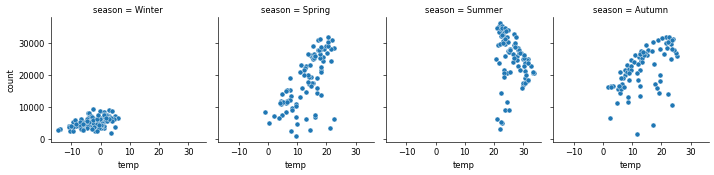


#### 3-3. 여름만 다른 계절과 상관관계의 방향이 다른 이유는 무엇이라고 생각하는가? 그리고 전체 상관계수 0.75 를 어떻게 해석해야 하는가?

---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

- 여름만 방향이 다른 이유:
- 전체 상관계수의 해석:

---

## 문제 4. 팀장에게 보고할 결론, 제안, 한계 작성 (제한시간 10분)

- 강의와 실습에서 확인한 결과를 바탕으로, 팀장의 질문 **"따릉이 대여량은 날씨와 요일에 따라 어떻게 달라지는가?"** 에 답하시오
- **결론**: 데이터에서 확인한 사실. 각 문장에 근거가 된 수치나 그래프를 함께 쓸 것
- **제안**: 결론을 바탕으로 운영팀이 검토해 볼 수 있는 일
- **한계**: 이 분석으로 말할 수 없는 것
- 강의 자료의 "팀장 보고 내용 (예시)" 형식을 참고할 것
- 다음 주부터 제출하는 분석 결과물도 같은 형식으로 작성하게 됨

---

##### 답안 (이 셀을 더블클릭하여 아래에 작성)

**결론 (3 ~ 5 문장)**

1.
2.
3.

**제안 (1 ~ 2 문장)**

1.

**한계 (1 ~ 2 문장)**

1.